<a href="https://colab.research.google.com/github/MariVahos/Analysis-Everpeak/blob/main/Copy_of_sesion_2_01_primera_api_trm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 1 · La TRM del día

**Análisis de Datos · Sesión 2 · Pedirle datos a una API**

La **TRM** (tasa representativa del mercado) es el precio oficial del dólar en Colombia. La certifica la Superintendencia Financiera y se publica en **datos.gov.co**, el portal de datos abiertos del Estado. Cualquiera puede pedirla con una API, sin clave.

**Cómo usar este notebook**

1. Menú **Archivo → Guardar una copia en Drive**. Trabaja sobre tu copia.
2. Ejecuta las celdas en orden con **Shift + Enter**.
3. Las celdas marcadas con ✍️ son para ti.

## 1. La primera petición

`requests` es la librería de Python para hablar con APIs. Ya viene instalada en Colab.

In [1]:
import requests
import pandas as pd

URL_TRM = "https://www.datos.gov.co/resource/32sa-8pi3.json"

In [2]:
respuesta = requests.get(
    URL_TRM,
    params={"$limit": 5, "$order": "vigenciadesde DESC"},
    timeout=30,
)

print("Código de estado:", respuesta.status_code)
print("Tipo de contenido:", respuesta.headers.get("Content-Type"))
print("URL que se pidió:", respuesta.url)

Código de estado: 200
Tipo de contenido: application/json;charset=utf-8
URL que se pidió: https://www.datos.gov.co/resource/32sa-8pi3.json?%24limit=5&%24order=vigenciadesde+DESC


Tres cosas para mirar:

- **Código 200**: la petición salió bien.
- **Tipo de contenido JSON**: la respuesta viene en formato JSON.
- **La URL**: `requests` armó la dirección completa con los parámetros. Los `$` y los espacios aparecen codificados (`%24`, `+`), así se escriben en una URL.

Ahora veamos los datos:

In [3]:
datos = respuesta.json()
datos

[{'valor': '3326.96',
  'unidad': 'COP',
  'vigenciadesde': '2026-11-19T00:00:00.000',
  'vigenciahasta': '2026-11-19T00:00:00.000'},
 {'valor': '3309.55',
  'unidad': 'COP',
  'vigenciadesde': '2026-11-18T00:00:00.000',
  'vigenciahasta': '2026-11-18T00:00:00.000'},
 {'valor': '3316.7',
  'unidad': 'COP',
  'vigenciadesde': '2026-11-14T00:00:00.000',
  'vigenciahasta': '2026-11-17T00:00:00.000'},
 {'valor': '3301.91',
  'unidad': 'COP',
  'vigenciadesde': '2026-11-13T00:00:00.000',
  'vigenciahasta': '2026-11-13T00:00:00.000'},
 {'valor': '3297.07',
  'unidad': 'COP',
  'vigenciadesde': '2026-11-11T00:00:00.000',
  'vigenciahasta': '2026-11-12T00:00:00.000'}]

Es una **lista de diccionarios**: cada diccionario es una fila y cada clave es una columna.

Fíjate en `valor`: viene entre comillas, como texto. Muchas APIs devuelven los números así, y hay que convertirlos.

## 2. De JSON a tabla

In [4]:
trm = pd.DataFrame(datos)
# Limpieza
trm["valor"] = trm["valor"].astype(float)
trm["vigenciadesde"] = pd.to_datetime(trm["vigenciadesde"])
trm["vigenciahasta"] = pd.to_datetime(trm["vigenciahasta"])
trm

,valor,unidad,vigenciadesde,vigenciahasta
0,3326.96,COP,2026-11-19,2026-11-19
1,3309.55,COP,2026-11-18,2026-11-18
2,3316.70,COP,2026-11-14,2026-11-17
3,3301.91,COP,2026-11-13,2026-11-13
4,3297.07,COP,2026-11-11,2026-11-12


**¿Qué representa una fila?** Un valor de la TRM y el periodo en el que estuvo vigente.

Mira `vigenciadesde` y `vigenciahasta`: en algunas filas no son el mismo día. ¿Por qué será? Pista: fines de semana y festivos.

## 3. Pedir solo lo que necesito

Esta API (se llama Socrata y la usan muchos gobiernos) entiende estos parámetros:

| Parámetro | Para qué sirve | Ejemplo |
|---|---|---|
| `$limit` | Cuántas filas traer (por defecto 1.000) | `5` |
| `$offset` | Desde qué fila empezar | `100` |
| `$order` | Cómo ordenar | `vigenciadesde DESC` |
| `$where` | Qué filas traer | `valor > 4000` |
| `$select` | Qué columnas traer | `valor, vigenciadesde` |

Pidamos toda la TRM de 2026:

Código: 200
Filas recibidas: 207


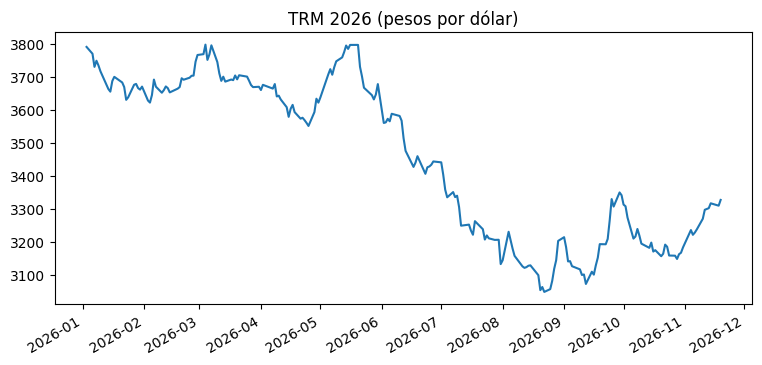

In [5]:
params = {
    "$where": "vigenciadesde >= '2026-01-01T00:00:00'",
    "$order": "vigenciadesde",
    "$limit": 1000,
}
r = requests.get(URL_TRM, params=params, timeout=30)
print("Código:", r.status_code)

trm_2026 = pd.DataFrame(r.json())
trm_2026["valor"] = trm_2026["valor"].astype(float)
trm_2026["vigenciadesde"] = pd.to_datetime(trm_2026["vigenciadesde"])
print("Filas recibidas:", len(trm_2026))

trm_2026.plot(x="vigenciadesde", y="valor", title="TRM 2026 (pesos por dólar)",
              legend=False, figsize=(9, 4), xlabel="");

Con dos parámetros cambiamos la pregunta: ya no son "las últimas 5 filas" sino "todo 2026, en orden".

## 4. Cuando algo sale mal

Las APIs avisan los problemas con el **código de estado**. Los que empiezan por 4 dicen "hay algo mal en tu petición". Los que empiezan por 5 dicen "falló el servidor".

Esta función muestra el error de forma legible:

In [7]:
def mostrar_error(r):
    print("Código:", r.status_code)
    try:
        cuerpo = r.json()
        print("Mensaje:", cuerpo.get("message", cuerpo))
    except ValueError:
        print("Respuesta:", r.text[:300])

In [8]:
# Error 1: ordenar por una columna que no existe
r = requests.get(URL_TRM, params={"$order": "precio DESC"}, timeout=30)
mostrar_error(r)

Código: 400
Mensaje: Query coordinator error: query.soql.no-such-column; No such column: precio; position: Map(row -> 1, column -> 69, line -> "SELECT `valor`, `unidad`, `vigenciadesde`, `vigenciahasta` ORDER BY `precio` DESC NULL FIRST\n                                                                    ^")


In [9]:
# Error 2: pedir un conjunto de datos que no existe
r = requests.get("https://www.datos.gov.co/resource/no-existe.json", timeout=30)
mostrar_error(r)

Código: 404
Mensaje: Not found


**Regla de oro:** revisa el código de estado antes de usar los datos. Si no lo haces, el error aparece más adelante y con un mensaje confuso.

Por eso, de aquí en adelante usaremos esta función, que se detiene apenas algo sale mal:

In [10]:
def pedir(url, params=None):
    r = requests.get(url, params=params, timeout=30)
    if r.status_code != 200:
        mostrar_error(r)
        raise RuntimeError(f"La API respondió {r.status_code}")
    return r.json()

ultimas = pedir(URL_TRM, {"$limit": 3, "$order": "vigenciadesde DESC"})
pd.DataFrame(ultimas)

,valor,unidad,vigenciadesde,vigenciahasta
0,3326.96,COP,2026-11-19T00:00:00.000,2026-11-19T00:00:00.000
1,3309.55,COP,2026-11-18T00:00:00.000,2026-11-18T00:00:00.000
2,3316.7,COP,2026-11-14T00:00:00.000,2026-11-17T00:00:00.000


## ✍️ Tu turno

1. ¿Cuál fue la **TRM más alta de 2025** y en qué fecha? Pista: usa `$where` para quedarte con 2025, `$order` con `valor DESC` y `$limit` igual a 1.
2. ¿Y la **más baja**?
3. Vuelve a la sección 3 y quita la línea de `$order`. ¿Cambia algo en la gráfica? ¿Por qué crees que pasa?
4. Provoca un **error 400** a propósito, con un `$where` mal escrito, y pega el mensaje en el chat.

In [13]:
# 1. TRM más alta de 2025
params = {
    "$where": "vigenciadesde >= '2025-01-01T00:00:00' AND vigenciadesde < '2026-01-01T00:00:00'",
    "$order": "Valor DESC", # ✍️ cámbialo para ordenar por valor, de mayor a menor
    "$limit": 1,
}
pedir(URL_TRM, params)

[{'valor': '4416.69',
  'unidad': 'COP',
  'vigenciadesde': '2025-04-10T00:00:00.000',
  'vigenciahasta': '2025-04-10T00:00:00.000'}]

In [14]:
# 2. TRM más baja de 2025
params = {
    "$where": "vigenciadesde >= '2025-01-01T00:00:00' AND vigenciadesde < '2026-01-01T00:00:00'",
    "$order": "Valor ASC", # ✍️ cámbialo para ordenar por valor, de mayor a menor
    "$limit": 1,
}
pedir(URL_TRM, params)

[{'valor': '3706.94',
  'unidad': 'COP',
  'vigenciadesde': '2025-12-25T00:00:00.000',
  'vigenciahasta': '2025-12-26T00:00:00.000'}]

In [ ]:
# 4. Un error 400 a propósito

---
**Si datos.gov.co no responde** (la celda se queda pensando o devuelve un código 5xx): espera un minuto y vuelve a ejecutar. Si sigue sin responder, avisa en el chat. Depender de un servicio externo también es parte del trabajo, y lo vamos a manejar en el notebook 3.